# Лабораторная работа №2: Исследовательский анализ данных (EDA)

#### __1. Формулировка бизнес-задачи__

__Цель работы:__ Провести разведочный анализ данных (EDA) для датасета задач Google Borg Cluster, визуализировать распределения признаков, выявить взаимосвязи и сформулировать выводы для дальнейшего моделирования.

#### __1. Загрузка данных и подготовка__

Загрузим очищенный датасет из первой лабораторной работы.

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Настройка отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Загрузка данных
df = pd.read_csv('Data\Dataset_1laba.csv', sep = ',', encoding='latin1')

# Настройка стиля графиков
sns.set_theme(style="whitegrid")

#### __2. Построение гистограмм и графиков плотности__

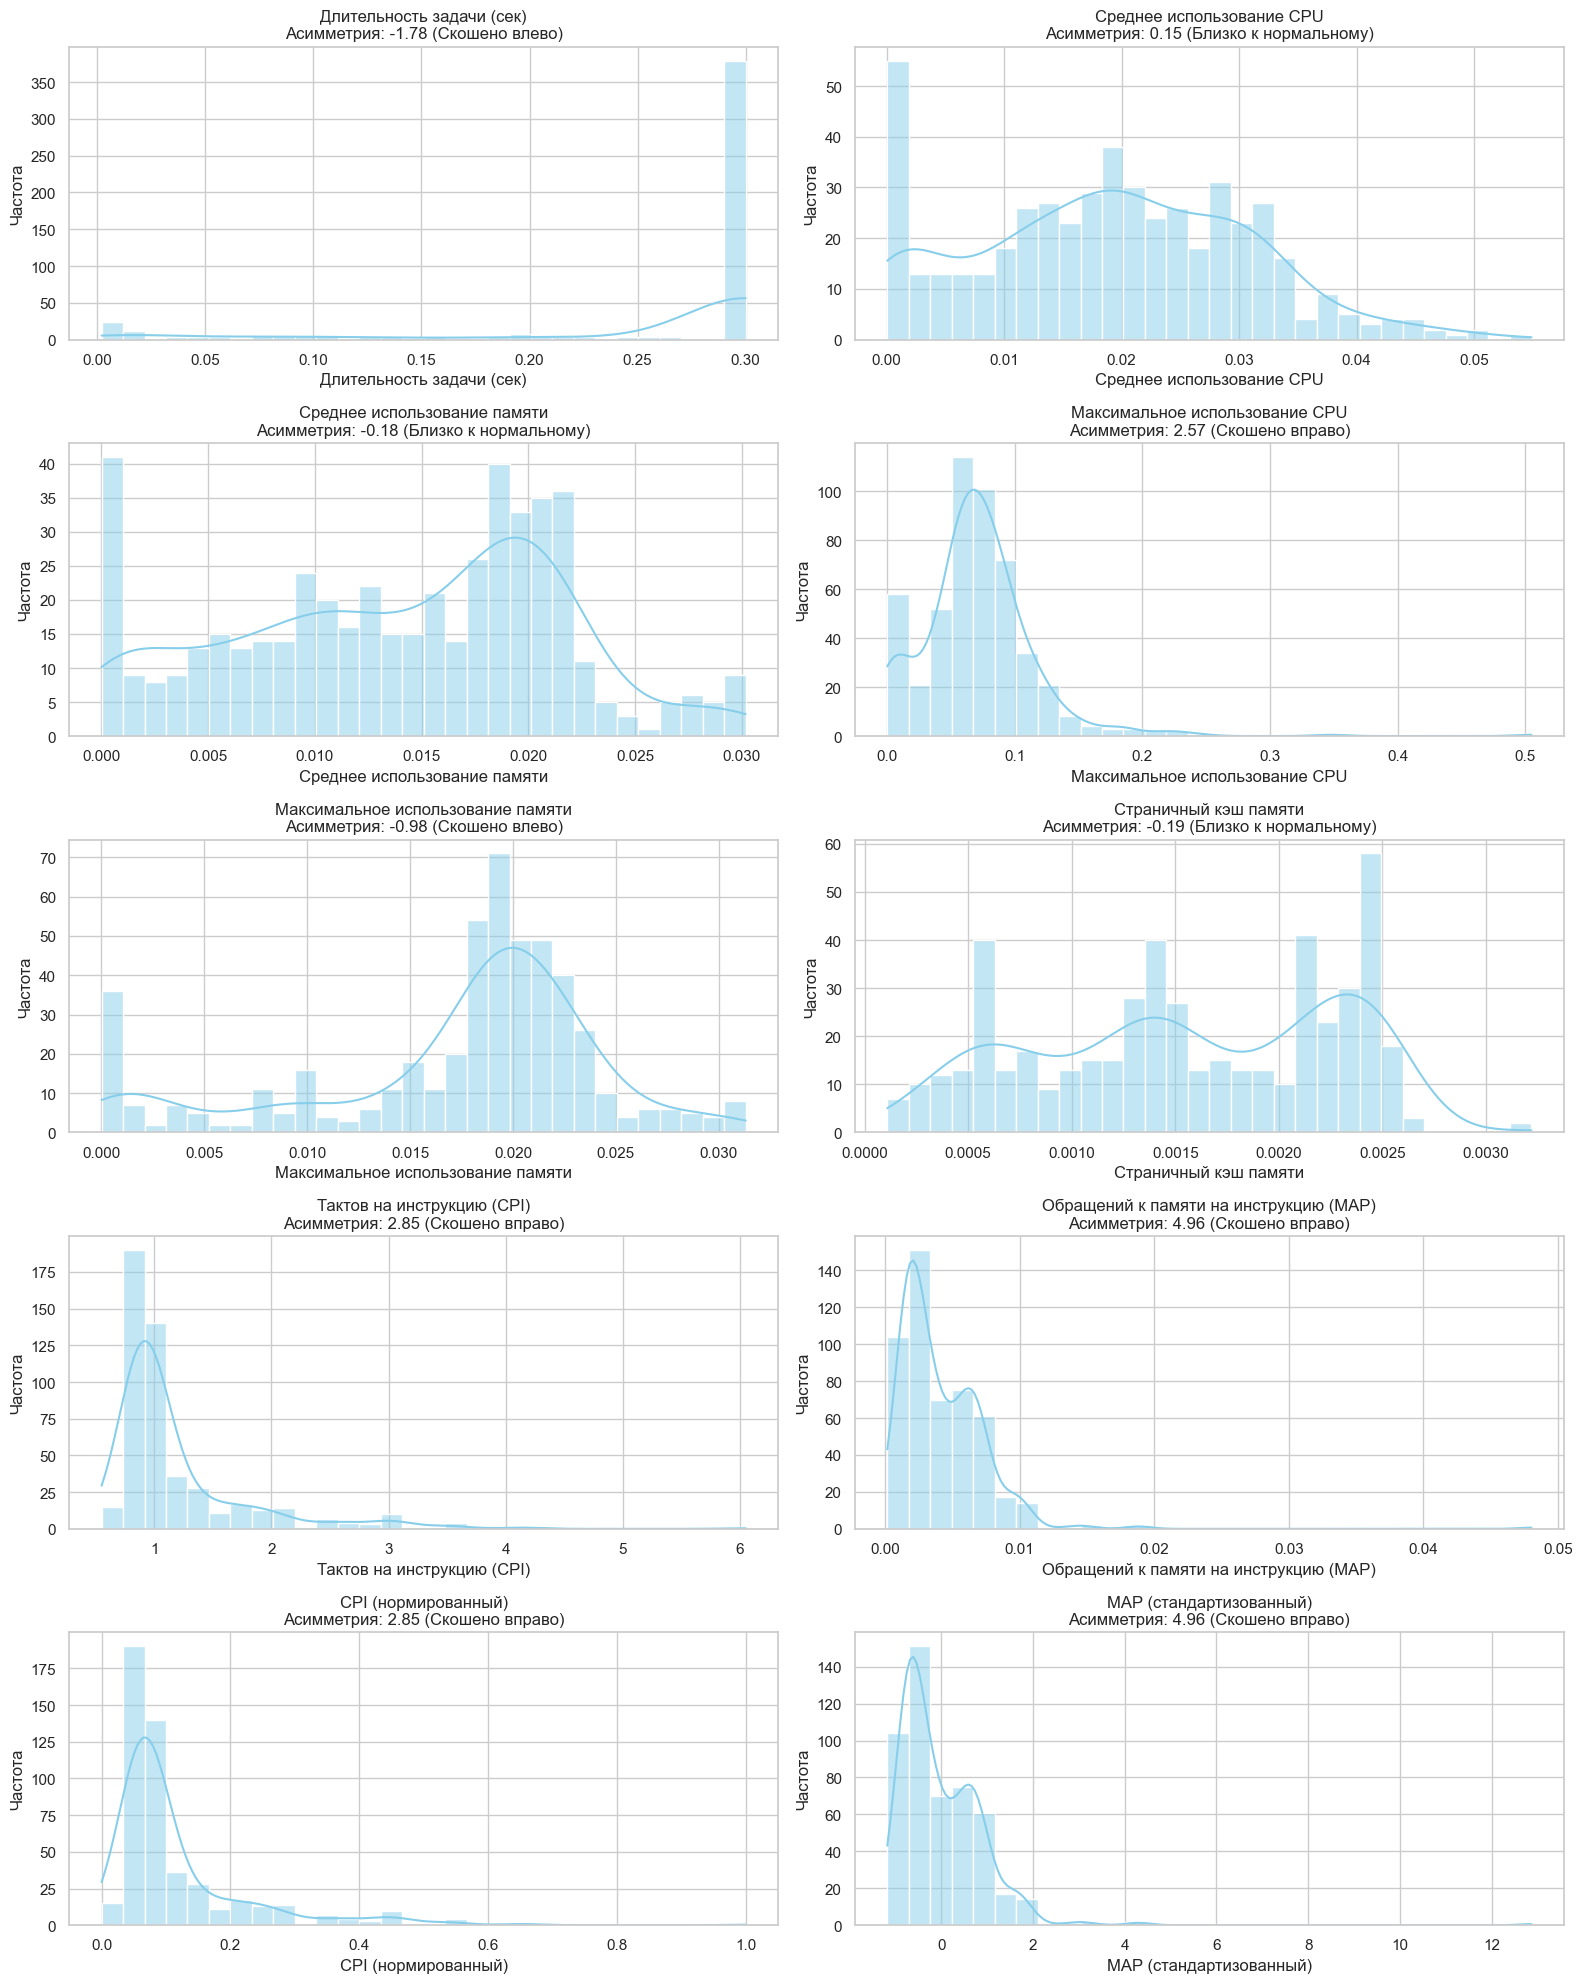

In [5]:
# Основные числовые признаки для анализа
numeric_features = ['duration', 'avg_cpus', 'avg_memory', 'max_cpus', 'max_memory',
                    'page_cache_memory', 'cycles_per_instruction',
                    'memory_accesses_per_instruction', 'cycles_per_instruction_norm',
                    'memory_accesses_per_instruction_std']

# Русские названия для признаков из датасета Google Cluster
rus_names = {
    'duration': 'Длительность задачи (сек)',
    'avg_cpus': 'Среднее использование CPU',
    'avg_memory': 'Среднее использование памяти',
    'max_cpus': 'Максимальное использование CPU',
    'max_memory': 'Максимальное использование памяти',
    'page_cache_memory': 'Страничный кэш памяти',
    'cycles_per_instruction': 'Тактов на инструкцию (CPI)',
    'memory_accesses_per_instruction': 'Обращений к памяти на инструкцию (MAP)',
    'cycles_per_instruction_norm': 'CPI (нормированный)',
    'memory_accesses_per_instruction_std': 'MAP (стандартизованный)'
}

# Построение гистограмм
plt.figure(figsize=(16, 20))  # Увеличил высоту, так как теперь 10 графиков
for i, col in enumerate(numeric_features, 1):
    plt.subplot(5, 2, i)  # Изменил на 5 строк и 2 столбца для 10 графиков
    # Строим график
    sns.histplot(df[col], kde=True, color='skyblue', bins=30)

    # Расчет асимметрии
    skewness = df[col].skew()
    if skewness > 0.5:
        shape = "Скошено вправо"
    elif skewness < -0.5:
        shape = "Скошено влево"
    else:
        shape = "Близко к нормальному"
    
    title_rus = rus_names.get(col, col)
    plt.title(f'{title_rus}\nАсимметрия: {skewness:.2f} ({shape})', fontsize=12)
    plt.xlabel(title_rus)
    plt.ylabel('Частота')

plt.tight_layout()
plt.show()

#### __3. Построение диаграмм «ящик с усами» для определения выбросов__

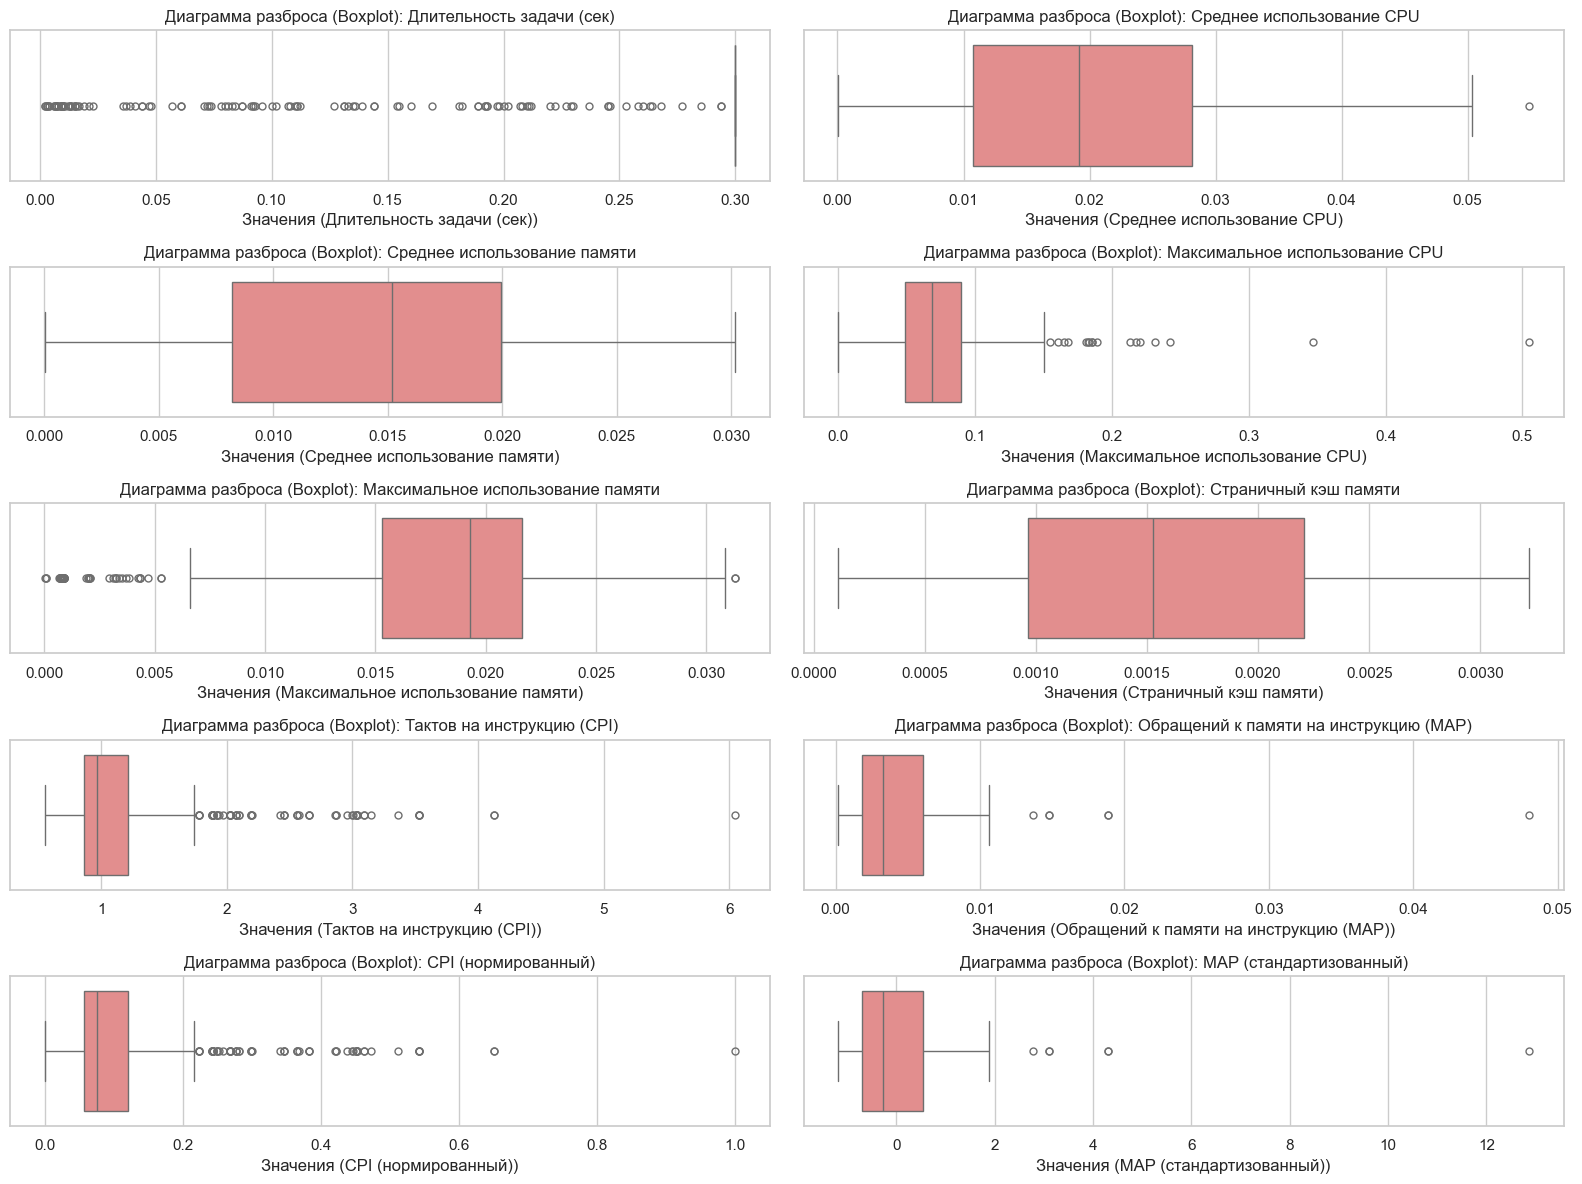

Анализ выбросов:
- duration: обнаружено 121 выбросов (границы: 0.30 - 0.30)
- avg_cpus: обнаружено 1 выбросов (границы: -0.02 - 0.05)
- avg_memory: обнаружено 0 выбросов (границы: -0.01 - 0.04)
- max_cpus: обнаружено 17 выбросов (границы: -0.01 - 0.15)
- max_memory: обнаружено 61 выбросов (границы: 0.01 - 0.03)
- page_cache_memory: обнаружено 0 выбросов (границы: -0.00 - 0.00)
- cycles_per_instruction: обнаружено 65 выбросов (границы: 0.33 - 1.74)
- memory_accesses_per_instruction: обнаружено 6 выбросов (границы: -0.00 - 0.01)
- cycles_per_instruction_norm: обнаружено 65 выбросов (границы: -0.04 - 0.22)
- memory_accesses_per_instruction_std: обнаружено 6 выбросов (границы: -2.54 - 2.39)


In [7]:
# Построение диаграмм «ящик с усами»
plt.figure(figsize=(16, 12))
for i, col in enumerate(numeric_features, 1):
    plt.subplot(5, 2, i)
    # Строим график
    sns.boxplot(x=df[col], color='lightcoral', fliersize=5)
    title_rus = rus_names.get(col, col)
    plt.title(f'Диаграмма разброса (Boxplot): {title_rus}', fontsize=12)
    plt.xlabel(f'Значения ({title_rus})')
plt.tight_layout()
plt.show()

#Вывод статистики по выбросам (метод IQR)
print("Анализ выбросов:")
for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"- {col}: обнаружено {len(outliers)} выбросов (границы: {lower_bound:.2f} - {upper_bound:.2f})")

#### __4. Анализ взаимосвязей между признаками__
Построим матрицу корреляции и диаграммы рассеяния для поиска зависимостей.

<Figure size 1200x1000 with 0 Axes>

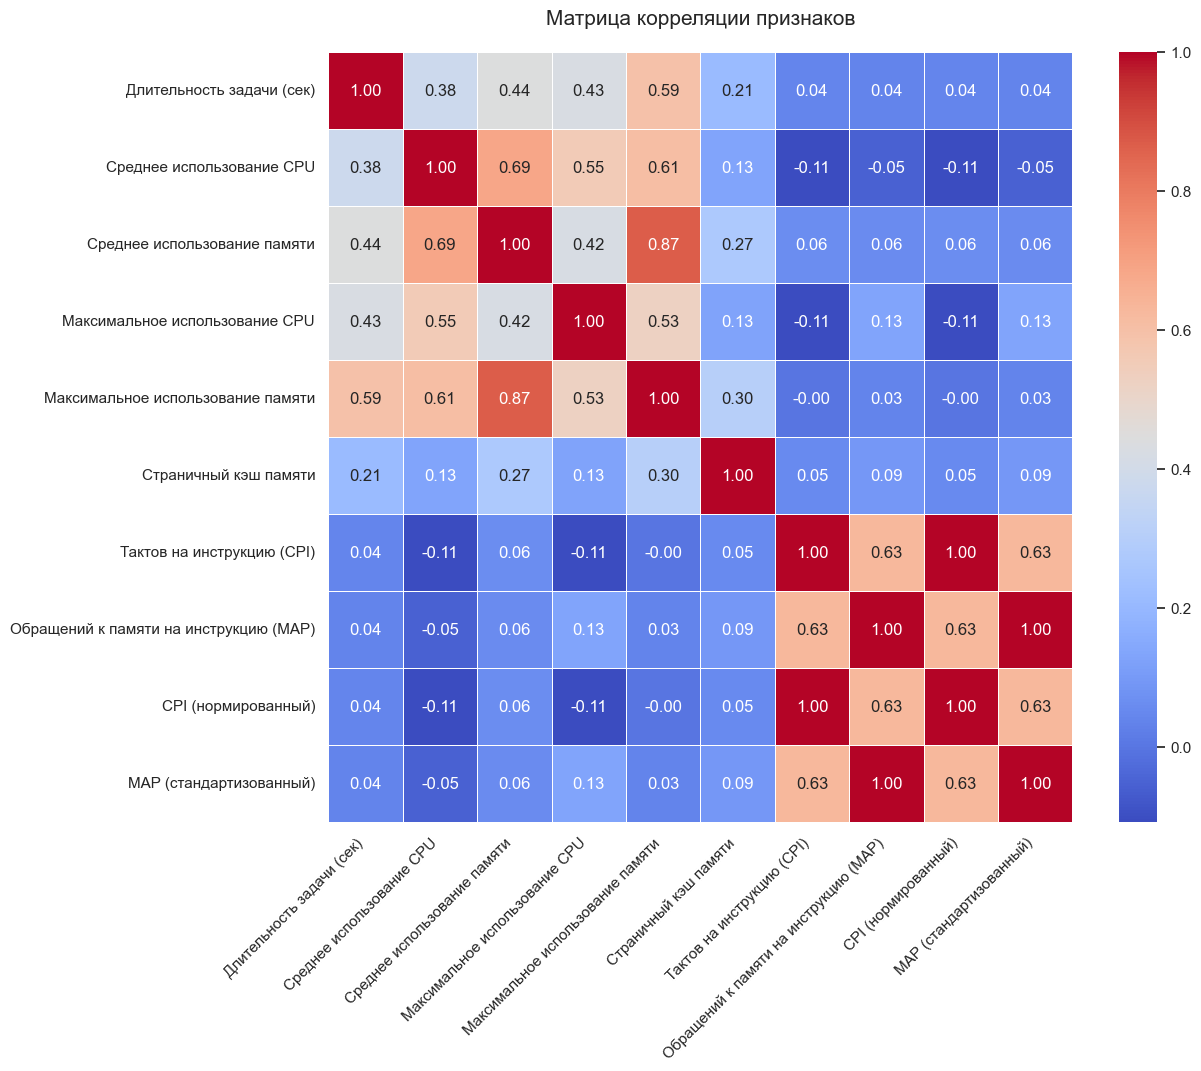

In [10]:
plt.figure(figsize=(12, 10))

numeric_df = df[['duration', 'avg_cpus', 'avg_memory', 'max_cpus', 'max_memory',
                    'page_cache_memory', 'cycles_per_instruction',
                    'memory_accesses_per_instruction', 'cycles_per_instruction_norm',
                    'memory_accesses_per_instruction_std']]
corr_matrix = numeric_df.corr()

labels_rus = [rus_names.get(col, col) for col in corr_matrix.columns]

#Строим тепловую карту
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, xticklabels=labels_rus, yticklabels=labels_rus)
plt.title('Матрица корреляции признаков', fontsize=15, pad=20)
plt.xticks(rotation=45, ha='right')
plt.show()

#### __5. Определение пар с высокой корреляцией__

In [11]:
# Определение пар с высокой корреляцией
print("Пары признаков с высокой корреляцией (|r| > 0.7):")
corr_unstacked = corr_matrix.unstack().sort_values(ascending=False)
# Убираем корреляцию признака самого с собой (1.0) и дубликаты
high_corr = corr_unstacked[(abs(corr_unstacked) > 0.7) & (abs(corr_unstacked) < 1.0)]
print(high_corr.drop_duplicates())

Пары признаков с высокой корреляцией (|r| > 0.7):
avg_memory  max_memory    0.866938
dtype: float64


#### __6. Диаграммы рассеяния для наиболее коррелированных пар__

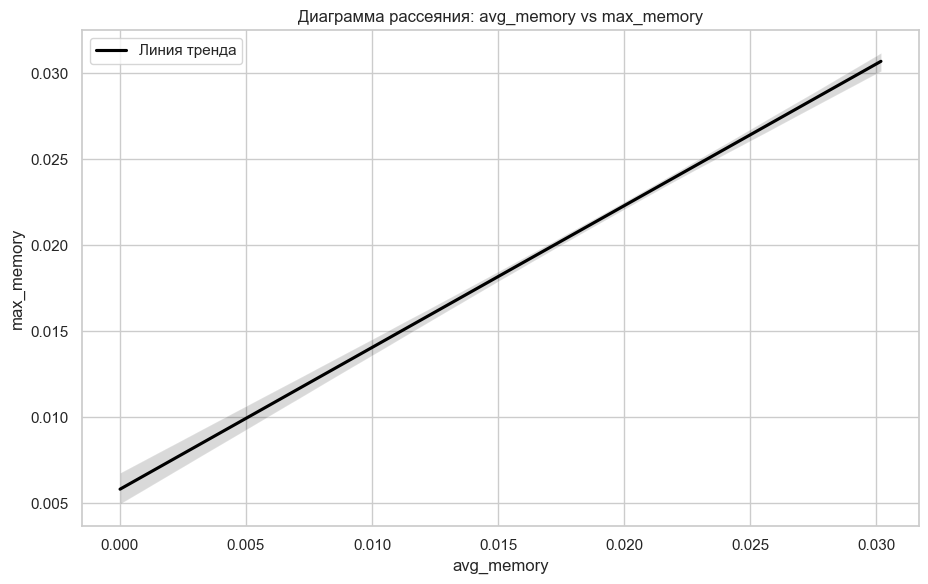

In [13]:
# Диаграммы рассеяния для наиболее коррелированных пар
target_pairs = [
    ('avg_memory', 'max_memory'),
]
plt.figure(figsize=(18, 6))

for i, (x_col, y_col) in enumerate(target_pairs, 1):
    plt.subplot(1, 2, i)
    # Добавляем линию тренда
    sns.regplot(data=df, x=x_col, y=y_col, scatter=False, color='black', label='Линия тренда')
    plt.title(f'Диаграмма рассеяния: {x_col} vs {y_col}')
    plt.legend()
plt.tight_layout()
plt.show()